### 비지도 학습
> 정답(`y`)없이 입력 데이터(피처, `X`)의 구조와 패턴을 학습하는 방법
|구분|지도학습|비지도학습|
|---|---|---|
|**데이터**|입력+정답(`fit(X,y)`)|입력만(`fit(X)`)|
|**목표**|정답을 예측／분류|숨은 패턴／구조 발견|
|**평가**|정답과 비교(정확도, f1등)|정량 지표(실루엣 etc.)+도메인 해석|

#### 대표적인 유형
- **군집화(Clustering)**: 비슷한 특성의 데이터끼리 그룹화
- **차원 축소(Dimensionality Reduction)**: 많은 피처를 적은 수의 핵심 축으로 압축 > 다중공선성 완화 및 시각화
> 다중공선성 완화 및 시각화
- **이상 탐지(Anomaly Detection)**: 정상 범위에서 벗어난 패턴 감지・이상 거래 및 급변 탐지
> 거리, 분산 기반 알고리즘이 많으므로 **스케일링이 필수**이며, 군집의 의미는 최종적으로 **도메인 지식**으로 검증해야 한다!

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from _style import setup
from _ml import load_merged, SEED

setup()
pd.set_option("display.width", 130)
print("준비 완료")

준비 완료


In [3]:
# 120개 종목을 수익률 패턴으로 군집화하고 실제 섹터와 비교
df = load_merged()

# 일간 수익률 피처 추가
df["ret"] = df.groupby("code")["close"].pct_change()

# 데이터를 (종목*날짜) 행렬로 만들기
    # 행 = 날짜, 열 = 종목, 값 = 수익률
pivot = df.pivot_table(index="date", columns="code", values="ret")

# 종목별 섹터
sector = df[["code", "sectorName"]].drop_duplicates().set_index("code")["sectorName"]
true_labels = sector[pivot.columns].values
print(f"수익률 행렬: {pivot.shape} (날짜 × 종목)")
print(f"군집화 입력: {pivot.T.shape} (종목 × 날짜)")
print("-" * 40) # ------------------------------------------------------
print(f"종목을 묶을 것이므로 '종목이 행'이 되도록 전치(.T)한다")
print(f"각 종목이 {pivot.shape[0]}개의 값으로 표현된다 (날짜별 수익률)")
print(f"섹터 {len(set(true_labels))}종류, 종목({len(true_labels)})개")
print(pd.DataFrame(true_labels).value_counts())
print("-" * 40) # ------------------------------------------------------

수익률 행렬: (749, 120) (날짜 × 종목)
군집화 입력: (120, 749) (종목 × 날짜)
----------------------------------------
종목을 묶을 것이므로 '종목이 행'이 되도록 전치(.T)한다
각 종목이 749개의 값으로 표현된다 (날짜별 수익률)
섹터 10종류, 종목(120)개
0    
금융       18
전기전자     16
IT서비스    14
유통       12
화학       12
바이오      12
운수장비     12
건설       10
에너지       8
식품        6
Name: count, dtype: int64
----------------------------------------


#### K-Means 군집화
> k개의 평균을 찾는 알고리즘
1. k개의 중심점을 선정
2. 각 데이터를 가장 가까운 중심점에 배정
3. 각 그룹의 평균으로 중심점을 이동
4. 중심점이 움직이지 않을 때까지 2、3번 반복

In [7]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import adjusted_rand_score, silhouette_score, davies_bouldin_score

def clustering(matrix, k=10, scale=True):
    """군집화하여 결과를 반환"""
    M = matrix.T.values
    if scale:
        M = StandardScaler().fit_transform(M)
    # km = KMeans(n_clusters=k)
    km = KMeans(
        n_clusters=k,
        random_state=SEED,      # 재현성
        n_init=10,              # n(10)번 시도해서 가장 좋은 결과를 고른다
    )
    pred = km.fit_predict(M)
    return pred, M, km          # (예측 결과, 입력 데이터(X), 모델)
preds, M_scaled, km = clustering(pivot, k=10, scale=True)
print("군집별 종목 수: ")
print(pd.Series(preds).value_counts().sort_index().to_string())

군집별 종목 수: 
0     5
1    18
2    25
3    14
4     2
5    15
6    13
7     7
8    12
9     9


**`random_state`, `n_init`을 둘 다 지정해야 매번 실행했을 때 동일한 결과를 확인할 수 있다 (재현성)**
> 실행하지 않으면 중심점을 무작위로 찍고 시작하기 때문에 실행마다 다른 군집이 나올 수 있다
- random_state=42: 랜덤 시드를 동일하게 주어 항상 같은 곳을 찍게한다
- n_init=10: 여러 번 시도해서 가장 좋은 결과를 고른다
---

In [8]:
lab_raw, M_raw, _ = clustering(pivot, k=10, scale=False)        # 스케일링 처리 X
lab_scaled, M_scaled, _ = clustering(pivot, k=10, scale=True)   # 스케일링 처리 O
vol = pivot.std()
rows = []
for name, lab in [("스케일링 X", lab_raw), ("스케일링 O", lab_scaled)]:
    # 각 군집의 평균 변동성을 구해서 가장 높은 군집과 가장 낮은 군집의 차이
    vol_by_cluster = pd.Series(vol.values).groupby(lab).mean()
    rows.append({
        "방식": name,
        "섹터와 일치(ARI)": adjusted_rand_score(true_labels, lab),
        "군집간 변동성 차이": vol_by_cluster.max() - vol_by_cluster.min()
    })
    # ARI: 두 그룹이 얼마나 일치하는가？、얼마나 비슷하게 잘 묶였는가？
        # 1.0: 완전 일치
        # 0.0: 무작위와 동일
        # 정답이 없는 비지도 학습이기 때문에 원래는 이 방식을 적용하기 어려우나、참고할 수 있는 데이터가 있으므로 비교가 가능하다
print(pd.DataFrame(rows).round(4).to_string(index=False))

    방식  섹터와 일치(ARI)  군집간 변동성 차이
스케일링 X       0.0333      0.0035
스케일링 O       0.5265      0.0053


**스케일링 없는 경우(X)는 섹터 구분이 전혀 안된다! (ARI 0.033)**
> K-Means는 거리로 판단하기 때문에 모든 종목에 똑같이 더해지는 시장 흐름은 종목 간 거리에서 상쇄될 것이다 \
> 대신 변동이 큰 날의 값이 거리를 좌우하기 때문에 섹터 차이가 묻히는 것으로 보여진다 \
> 하지만, 스케일링(StandardScaler)을 적용하면 ARI가 0.53까지 올라간다!

**스케일링한 군집 결과를 섹터와 비교**

In [9]:
cross_table = pd.crosstab(pd.Series(lab_scaled, name="군집"), pd.Series(true_labels, name="섹터"))
most = cross_table.max(axis=1).sum()
print(f"군집 순도: {most/cross_table.values.sum():.2f}")

군집 순도: 0.72


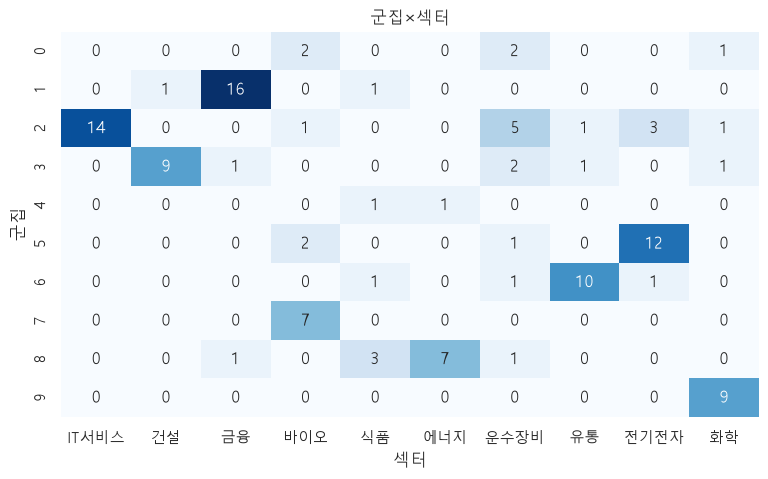

In [10]:
import seaborn as sns
fig, ax = plt.subplots(figsize=(9, 5))
sns.heatmap(cross_table, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
ax.set_title("군집×섹터")
plt.show()

**군집 결과 (k=10、스케일링 적용)**
> 순도 0.72: 각 군집에서 가장 많은 섹터의 종목 수를 모두 더해 전체 종목 수(120)로 나눈 값
  - 1.0이면 군집과 섹터가 일치한다
> 잘 묶여진 섹터: IT 서비스 (14/14)・금융(16/18)・건설(9/10)・유통(10/12)・화학(9/12)・전기전자(12/16) \
> 섞인 것: 운수장비(12)는 어느 군집도 주도하지 못하고 흩어진다(최대 5)
  - 군집 8번은 에너지(7)・식품(3)가 섞인다 군집 0번・4번은 작게 섞여있는 군집
> 순도는 군집수가 많을수록 높아지기 쉬운 지표이다 (k=종목수 > 1.0)
  - 그렇기 때문에 ARI(0.53)와 같이 분석해야 한다
> 같은 섹터 종목이 비슷하게 움직인다는 가정은 대체로 맞다
  - 다만 운수장비처럼 수익률 패턴이 섹터 안에서 제각각인 경우는 수익률만으로는 구분이 어렵다.
---
#### k를 정하는 방법
|방법|보는 관점|방향|
|---|---|---|
|엘보|K를 늘릴수록 오차가 줄어든다・꺾이는 지점|-|
|실루엣 계수|군집 안은 뭉치고／군집 간은 떨어졌는가？|높을수록 좋다|
|DBI|군집끼리 잘 분리되었는가？|낮을수록 좋다|

In [11]:
ks = range(2, 16)
rows = []
for k in ks:
    # k값을 변경하면서 KMeans 모델 생성 > 군집화
    km_k = KMeans(n_clusters=k, random_state=SEED, n_init=10).fit(M_scaled)
    lab_k = km_k.labels_
    rows.append({
        "k": k,
        "관성": km_k.inertia_,      # 엘보 확인용・낮을수록 좋다
        "실루엣": silhouette_score(M_scaled, lab_k),        # 높을수록 좋다・군집간 분리도와 내부 응집도 종합
        "DBI": davies_bouldin_score(M_scaled, lab),         # 낮을수록 좋다
        "ARI(참고)": adjusted_rand_score(true_labels, lab_k)
    })
    k_table = pd.DataFrame(rows)
    print(k_table.round(4).to_string(index=False))

 k         관성    실루엣    DBI  ARI(참고)
 2 86829.6581 0.0249 3.7209   0.1593
 k         관성    실루엣    DBI  ARI(참고)
 2 86829.6581 0.0249 3.7209   0.1593
 3 85487.7156 0.0163 3.7209   0.2217
 k         관성    실루엣    DBI  ARI(참고)
 2 86829.6581 0.0249 3.7209   0.1593
 3 85487.7156 0.0163 3.7209   0.2217
 4 84580.5442 0.0139 3.7209   0.2523
 k         관성    실루엣    DBI  ARI(참고)
 2 86829.6581 0.0249 3.7209   0.1593
 3 85487.7156 0.0163 3.7209   0.2217
 4 84580.5442 0.0139 3.7209   0.2523
 5 83066.5696 0.0134 3.7209   0.2501
 k         관성    실루엣    DBI  ARI(참고)
 2 86829.6581 0.0249 3.7209   0.1593
 3 85487.7156 0.0163 3.7209   0.2217
 4 84580.5442 0.0139 3.7209   0.2523
 5 83066.5696 0.0134 3.7209   0.2501
 6 82233.8038 0.0084 3.7209   0.2950
 k         관성    실루엣    DBI  ARI(참고)
 2 86829.6581 0.0249 3.7209   0.1593
 3 85487.7156 0.0163 3.7209   0.2217
 4 84580.5442 0.0139 3.7209   0.2523
 5 83066.5696 0.0134 3.7209   0.2501
 6 82233.8038 0.0084 3.7209   0.2950
 7 80815.0873 0.0141 3.7209   0.4656
 

----------------------------------------


AttributeError: 'Series' object has no attribute 'idmax'

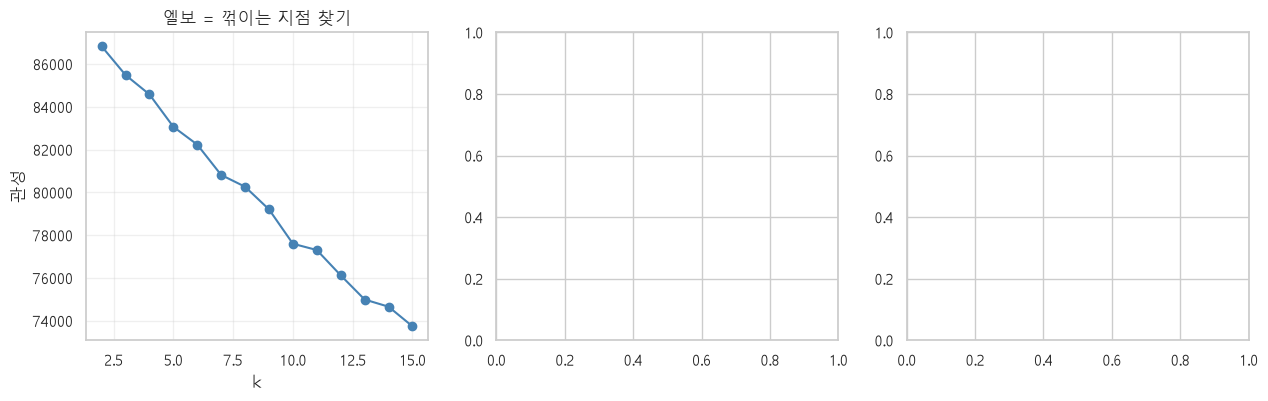

: 

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# 엘보우
axes[0].plot(k_table["k"], k_table["관성"], "o-", color="steelblue")

axes[0].set_xlabel("k")
axes[0].set_ylabel("관성")
axes[0].set_title("엘보 = 꺾이는 지점 찾기")
axes[0].grid(alpha=0.3)
print("-" * 40) # ------------------------------------------------------

# 실루엣
best_sil = k_table.loc[k_table["실루엣"].idmax(), "k"]
axes[1].axvline(best_sil, color="gray", ls="--", lw=1, label=f"최대 k={best_sil}")
axes[1].plot(k_table["k"], k_table["실루엣"], "o-", color="seagreen")

axes[1].set_xlabel("k")
axes[1].set_ylabel("실루엣 계수")
axes[1].set_title("실루엣 = 높을수록 좋다")
axes[1].legend()
axes[1].grid(alpha=0.3)
print("-" * 40) # ------------------------------------------------------

# DBI
axes[2].plot(k_table["k"], k_table["DBI"], "o-", color="IndianRed")
best_dbi = k_table.loc[k_table["DBI"].idxmin(), "k"]
axes[2].axvline(best_dbi, color="gray", ls="--", lw=1, label=f"최소 k={best_dbi}")
axes[2].set_xlabel("k")
axes[2].set_ylabel("DBI")
axes[2].set_title("DBI = 낮을수록 좋다")
axes[2].legend()
axes[2].grid(alpha=0.3)
fig.tight_layout()
plt.show()

**1. 엘보가 뚜렷하지 않는다**
> 관성 곡선이 완만하게 내려가기만 해서 어디가 팔꿈치 지점인지 알 수 없다 → 일반적인 현상

**2. 실루엣이 매우 낮다 (0.02 수준)**
> 군집이 뚜렷하게 나뉘지 않는다 → 금융 수익률 데이터에서는 일반적이다

**3. 모든 지표가 다른 K가 좋다고 한다**
> 실루엣이 작은 k, DBI가 큰 k가 각각 있다／어느 하나를 기계적으로 믿으면 안된다! \
> 결국 도메인 지식이 필요하다 → 섹터가 10개이므로、k=10